In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'scrapy.cfg').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from quality.analyze import analyze
frames, stats, summary = analyze()
display(pd.DataFrame({'записей': summary['tables'], 'уникальных ключей': summary['unique_keys']}))

,записей,уникальных ключей
books,299,299
quotes,97,97


# Часть 1. Сбор данных в Scrapy

В одном проекте работают два паука: Books to Scrape и Quotes to Scrape. Они проходят списки, затем карточки книг и страницы авторов. Контекст передаётся через cb_kwargs. Получены 299 книг и 97 цитат.

Код пауков находится в lab5_crawler/spiders. Схема записи - в items.py, четыре этапа обработки - в pipelines.py, настройки - в settings.py. Команда python run_lab.py all выполняет сбор и опыты.

### 1.1. Обработка и настройки

Пайплайн проверяет обязательные поля, очищает значения, удаляет дубли и записывает данные в SQLite пакетами по 25. Ключ книги - UPC, ключ цитаты - автор и текст.

Учитывается robots.txt. Заданы два запроса на домен, пауза 0,5 секунды и AutoThrottle. Ограничители: 350 записей, 500 ответов, 900 секунд и глубина 60. Используется Spider с явной пагинацией response.follow.

### 1.2. Полнота и типы

Проверим заполненность полей и уникальность ключей. Строки без обязательных полей отбрасываются до записи в базу.

In [2]:
display(pd.DataFrame(summary['completeness']))
display(frames['books'].dtypes.to_frame('тип в pandas'))
display(frames['quotes'][['author','born_date']].head())
assert pd.to_datetime(frames['quotes']['born_date'], format='%Y-%m-%d').notna().all()

,table,field,filled_pct
0,books,upc,100.0
1,books,title,100.0
2,books,price_excl_tax,100.0
3,books,stock_count,100.0
4,books,review_count,100.0
5,books,category,100.0
6,books,description,100.0
7,books,rating,100.0
8,books,source_url,100.0
9,books,list_url,100.0


,тип в pandas
upc,str
title,str
price_excl_tax,float64
stock_count,int64
review_count,int64
category,str
description,str
rating,int64
source_url,str
list_url,str


,author,born_date
0,Steve Martin,1945-08-14
1,Thomas A. Edison,1847-02-11
2,André Gide,1869-11-22
3,Marilyn Monroe,1926-06-01
4,Jane Austen,1775-12-16


### 1.3. Статистика сбора

Из статистики читаются число страниц и карточек, HTTP-статусы, повторы и причины отбраковки. body_bytes содержит объём тел HTML.

In [3]:
display(pd.DataFrame(summary['counters']).fillna(0))
display(pd.Series({k: summary[k] for k in ['records','seconds','network_requests','body_bytes','download_bytes','retries']}))
print('Пустых обязательных полей в БД:', summary['empty_required_rows_in_db'])

,books,quotes
downloader/response_status_count/404,1.0,1.0
downloader/response_status_count/200,315.0,60.0
source/list_pages,15.0,10.0
source/detail_pages,300.0,50.0
pipeline/validated,299.0,97.0
pipeline/cleaned,299.0,97.0
pipeline/unique,299.0,97.0
database/batches,12.0,4.0
database/written,299.0,97.0
database/written/books,299.0,0.0


records             3.960000e+02
seconds             2.917916e+02
network_requests    4.270000e+02
body_bytes          6.858679e+06
download_bytes      6.976563e+06
retries             0.000000e+00
dtype: float64

Пустых обязательных полей в БД: 0


### 1.4. Анализ данных

Рассчитаем среднюю цену по категориям, распределение рейтингов и число цитат по авторам.

In [4]:
display(pd.DataFrame(summary['categories']).head(10))
display(pd.DataFrame(summary['ratings']))
display(pd.DataFrame(summary['authors']).head(10))

,category,books,avg_price_gbp
0,Default,46,34.90
1,Sequential Art,34,33.83
2,Nonfiction,33,30.35
3,Fiction,19,38.25
4,Young Adult,15,32.07
5,Fantasy,14,38.02
6,Add a comment,12,33.28
7,Poetry,11,36.96
8,Food and Drink,11,34.65
9,Romance,10,29.63


,rating,books
0,1,67
1,2,64
2,3,54
3,4,55
4,5,59


,author,quotes
0,Albert Einstein,10
1,J.K. Rowling,8
2,Dr. Seuss,6
3,Marilyn Monroe,6
4,Mark Twain,6
5,Jane Austen,5
6,C.S. Lewis,5
7,Bob Marley,3
8,Charles Bukowski,2
9,Suzanne Collins,2


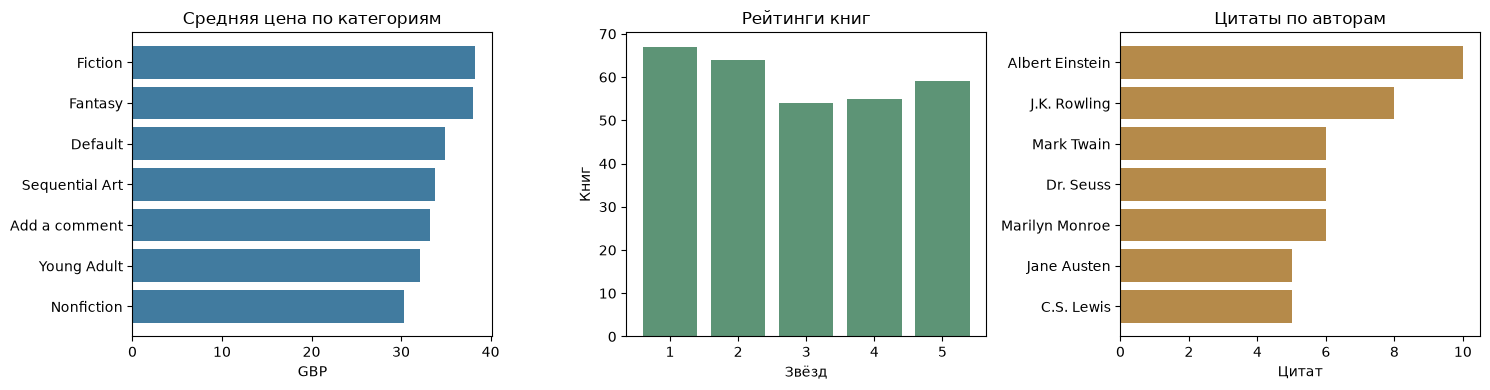

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
categories = pd.DataFrame(summary['categories']).head(7).sort_values('avg_price_gbp')
axes[0].barh(categories.category, categories.avg_price_gbp, color='#417b9f')
axes[0].set_title('Средняя цена по категориям'); axes[0].set_xlabel('GBP')
ratings = pd.DataFrame(summary['ratings'])
axes[1].bar(ratings.rating, ratings.books, color='#5d9476')
axes[1].set_title('Рейтинги книг'); axes[1].set_xlabel('Звёзд'); axes[1].set_ylabel('Книг')
authors = pd.DataFrame(summary['authors']).head(7).sort_values('quotes')
axes[2].barh(authors.author, authors.quotes, color='#b58a4a')
axes[2].set_title('Цитаты по авторам'); axes[2].set_xlabel('Цитат')
fig.tight_layout()
plt.show()

### 1.5. Продолжение сбора и HTTP-кэш

JOBDIR сохраняет очередь и посещённые адреса. После остановки продолжаем тот же сбор. В отдельном опыте дважды загружаем одну страницу каталога с включённым HTTP-кэшем.

In [6]:
experiments = json.loads((ROOT/'data/experiments.json').read_text(encoding='utf-8'))
rows = []
for group, keys in [('resume',['first','second']), ('cache',['cold','warm'])]:
    for key in keys:
        run = experiments[group][key]
        st = json.loads((ROOT/f'data/stats_{run}.json').read_text(encoding='utf-8'))
        rows.append({'опыт':group+' / '+key, 'записей':st.get('item_scraped_count',0),
            'секунд':round(st['elapsed_time_seconds'],2), 'dupefilter':st.get('dupefilter/filtered',0),
            'cache_hit':st.get('httpcache/hit',0), 'cache_store':st.get('httpcache/store',0)})
display(pd.DataFrame(rows))
print('Повторно разобранные URL после продолжения:', experiments['resume']['repeated_parsed_urls'])
print('Всего книг в опыте JOBDIR:', experiments['resume']['total_records'])

,опыт,записей,секунд,dupefilter,cache_hit,cache_store
0,resume / first,29,20.44,0,0,0
1,resume / second,71,47.01,1,0,0
2,cache / cold,20,13.59,0,0,22
3,cache / warm,20,1.48,0,22,0


Повторно разобранные URL после продолжения: []
Всего книг в опыте JOBDIR: 100


### 1.6. Проверка изменений

Smoke-check предупреждает при падении числа записей более чем на 20% или пустых обязательных полях более чем у 5% строк. Ниже показаны результат текущего сбора и отдельные тестовые случаи.

In [7]:
print(json.dumps(summary['smoke'], ensure_ascii=False, indent=2))
display(pd.DataFrame(summary['smoke_examples']).T)

{
  "status": "OK",
  "warnings": [],
  "has_previous_run": false
}


,status,warnings,has_previous_run
normal,OK,[],True
decrease_30_percent,WARNING,[Число записей упало на 30.0%],True
empty_6_percent,WARNING,[Пустые обязательные поля: 6.0% записей],True


# Часть 2. Сбор данных в n8n

Сценарий загружает две страницы каталога, извлекает ссылки и обходит 40 карточек в цикле. Между порциями используется Wait. Поля приводятся к нужным типам, дубликаты удаляются, результат сохраняется в CSV.

На сетевых узлах настроены повторные попытки и ветка ошибки. Расписание на 09:00 по Перми выключено до публикации workflow.

### 2.1. Сравнение результатов

Сравним одинаковые 40 книг. В таблице приведены сохранённые контрольные замеры. Полный сбор Scrapy содержит 396 записей.

In [8]:
saved = json.loads((ROOT / 'results.json').read_text(encoding='utf-8'))
display(pd.DataFrame(saved['comparison']))
benchmark = json.loads((ROOT / 'data/benchmark.json').read_text(encoding='utf-8'))
python_sample = pd.read_json(ROOT / f"data/items_{benchmark['run_id']}.jsonl", lines=True)
nocode = pd.read_csv(ROOT / 'nocode/nocode_result.csv')
fields = ['upc','title','price_excl_tax','stock_count','review_count','category','description','rating','source_url']
left = python_sample[fields].sort_values('upc').reset_index(drop=True)
right = nocode[fields].sort_values('upc').reset_index(drop=True)
pd.testing.assert_frame_equal(left, right, check_dtype=False)
print('Совпали', len(left), 'книг и все общие поля.')
display(nocode.head())

,Метрика,Scrapy,n8n
0,Записей в одинаковой выборке,40,40
1,"Время прогона, с",26.912,85.907
2,Записей в минуту,89.18,27.94
3,Сетевых запросов (с robots.txt),43,42
4,Запросов списков и карточек,42,42
5,"Тела HTML, МБ",0.840684,0.840684
6,Дедупликация запросов,Dupefilter + JOBDIR,Нет; Remove Duplicates очищает записи
7,Продолжение после остановки,"JOBDIR, проверено",В этой схеме повторный запуск целиком
8,Расписание и уведомления,Нужен внешний запуск; журнал ошибок,Schedule + локальное уведомление об ошибке
9,Версионирование,Python-файлы и настройки в Git,Экспорт JSON в Git


Совпали 40 книг и все общие поля.


,upc,title,price_excl_tax,stock_count,review_count,category,description,rating,source_url
0,a897fe39b1053632,A Light in the Attic,51.77,22,0,Poetry,It's hard to imagine a world without A Light i...,3,https://books.toscrape.com/catalogue/a-light-i...
1,90fa61229261140a,Tipping the Velvet,53.74,20,0,Historical Fiction,"""Erotic and absorbing...Written with starling ...",1,https://books.toscrape.com/catalogue/tipping-t...
2,6957f44c3847a760,Soumission,50.10,20,0,Fiction,"Dans une France assez proche de la nôtre, un h...",1,https://books.toscrape.com/catalogue/soumissio...
3,e00eb4fd7b871a48,Sharp Objects,47.82,20,0,Mystery,"WICKED above her hipbone, GIRL across her hear...",4,https://books.toscrape.com/catalogue/sharp-obj...
4,4165285e1663650f,Sapiens: A Brief History of Humankind,54.23,20,0,History,From a renowned historian comes a groundbreaki...,5,https://books.toscrape.com/catalogue/sapiens-a...


### 2.2. Схема и успешный запуск

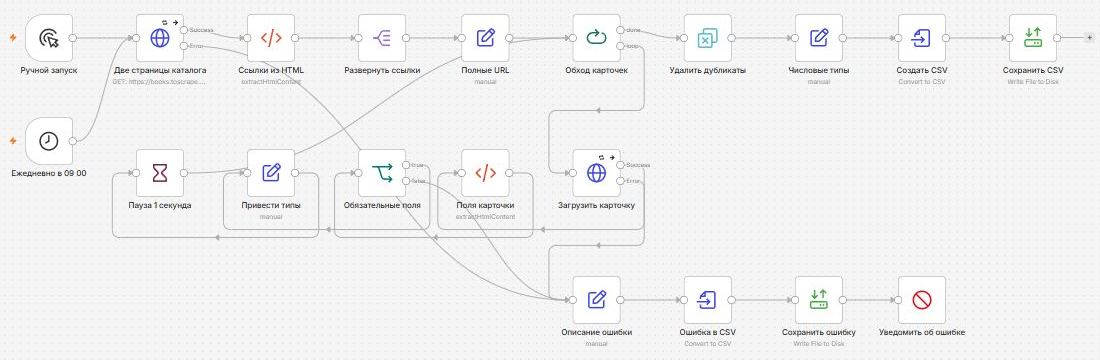

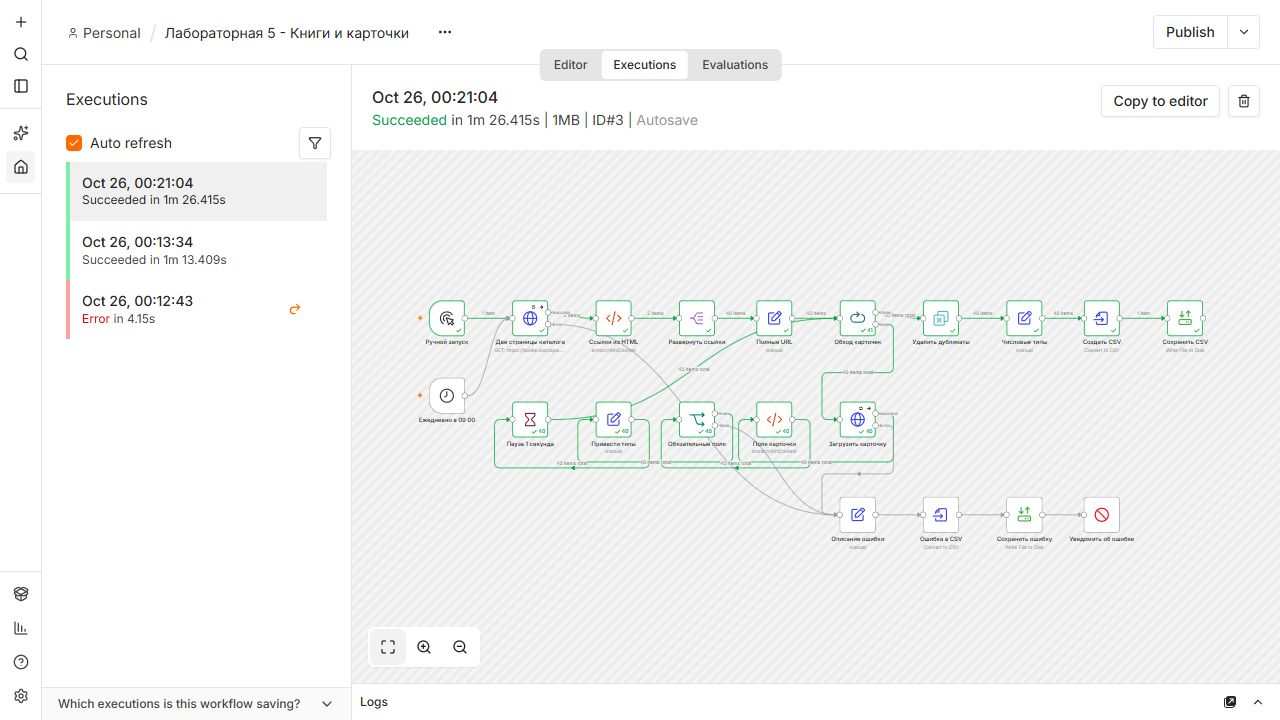

In [9]:
for name in ["screenshot_workflow.png", "screenshot_success.png"]:
    display(Image(filename=str(ROOT / "nocode" / name), width=1000))

# Итоговый вывод

Scrapy собрал 396 записей: 299 книг и 97 цитат. Отброшены одна книга без описания и три цитаты без тегов. JOBDIR продолжил сбор без повторных URL, HTTP-кэш повторно использовал сохранённые ответы. Выборка n8n совпала с результатом Scrapy.

Для разового обхода 500 страниц и ежедневного обхода 40 000 страниц подходит Scrapy. Для сотни страниц с отправкой отчёта удобен n8n. Их можно совместить: Scrapy собирает данные, n8n запускает процесс и готовит уведомление.

При редизайне могут измениться классы карточек и таблицы. Smoke-check обнаруживает рост пропусков и падение объёма.

### Источники
- [Books to Scrape](https://books.toscrape.com/)
- [Quotes to Scrape](https://quotes.toscrape.com/)
- [Scrapy](https://docs.scrapy.org/en/latest/)
- [n8n](https://docs.n8n.io/)